In [1]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 39.2 MB/s  0:00:02


In [116]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.utils import resample

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    recall_score,
    precision_score,
    fbeta_score,
    confusion_matrix,
    brier_score_loss,
    accuracy_score)
from sklearn.linear_model import LogisticRegression
from catboost import CatBoostClassifier, Pool
from sklearn.impute import SimpleImputer
import lightgbm as lgb
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier, DMatrix
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV, cross_val_score
from IPython.display import display, FileLink

from imblearn.over_sampling import RandomOverSampler, SMOTE, ADASYN

import random

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
rng = np.random.default_rng(SEED)

## Preprocessing data

Выделяются 2 группы фичей
- features_1 - лучшие на основе 500 итераций бутстрапа
- features_2 - отобранные на 2 встрече по медицинской специфике влияния на таргет

In [141]:
df = pd.read_excel("data.xlsx")
df.head(5)

features_no_exp = ['пол', 'возр', 'Алкоголь', 'бледность', 'гиперемия коньюктив', 'гиперемия', 'Ps', 'тошнота',
            'Гипертонус','Hb','эр','ЦП','глюкоза','COHb 1', 'ЭКГ', 'Сознание', 'Психика', 'г боли', 'шум в ушах, голове','Пирсс',
             'АД с', 'АД д', 'Нистагм', 'осиплость голоса', 'судорги']

features_exp = features_no_exp + ['экспозиция']
target = 'к/д реан'

def prepare_to_num(feature_type, drop_na=False, exposion=False):
  df_new = df[feature_type + [target]].copy()
  if 'ЭКГ' in feature_type:
      df_new['ЭКГ'] = (df_new['ЭКГ'] != 'норма').astype(float)
  if 'глюкоза' in feature_type:
    df_new['глюкоза'] = pd.to_numeric(df_new['глюкоза'].astype(str).str.strip().str.replace(',,', '.', regex=False).str.replace(',', '.', regex=False), errors='coerce')
  if exposion:
    df_new['экспозиция'] = pd.to_numeric(df_new['экспозиция'].astype(str).str.strip().str.replace('неизв', '', regex=False), errors='coerce')
  if drop_na:
    df_new = df_new.dropna().reset_index(drop=True)
  X = df_new[feature_type].copy()
  y = (df_new[target] > 0).astype(int)
  return X, y


def impute_nan_train_test(X_train, X_test):
  cat_features = [col for col in X_train.columns if X_train[col].nunique() <= 5]
  num_features = [col for col in X_train.columns if col not in cat_features]
  num_imputer = SimpleImputer(strategy="median")
  cat_imputer = SimpleImputer(strategy="most_frequent")
  X_train[num_features] = num_imputer.fit_transform(X_train[num_features])
  X_train[cat_features] = cat_imputer.fit_transform(X_train[cat_features])

  X_test[num_features] = num_imputer.transform(X_test[num_features])
  X_test[cat_features] = cat_imputer.transform(X_test[cat_features])
  return X_train, X_test

def standartize_train_test(X_train, X_test):
  scaler = StandardScaler()
  X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])
  X_test[scale_cols] = scaler.transform(X_test[scale_cols])
  return X_train, X_test


In [ ]:
X_nan, y_nan = prepare_to_num(features_no_exp)
X_l1_reg, y_l1_reg = prepare_to_num(features_no_exp, True)
X_eposion, y_exp = prepare_to_num(features_exp, False, True)
X, y = prepare_to_num(features_exp, False, True)

X_eposion_no_nan, y_exp_no_nan = prepare_to_num(features_exp, True, True)

In [119]:
print(y_exp_no_nan.shape[0] - y_exp_no_nan.sum(), y_exp_no_nan.sum()) # class 0 vs 1

90 27


In [110]:
X_l1_reg.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 142 entries, 0 to 141
Data columns (total 25 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   пол                  142 non-null    int64  
 1   возр                 142 non-null    int64  
 2   Алкоголь             142 non-null    int64  
 3   бледность            142 non-null    int64  
 4   гиперемия коньюктив  142 non-null    int64  
 5   гиперемия            142 non-null    int64  
 6   Ps                   142 non-null    int64  
 7   тошнота              142 non-null    int64  
 8   Гипертонус           142 non-null    int64  
 9   Hb                   142 non-null    float64
 10  эр                   142 non-null    float64
 11  ЦП                   142 non-null    float64
 12  глюкоза              142 non-null    float64
 13  COHb 1               142 non-null    float64
 14  ЭКГ                  142 non-null    float64
 15  Сознание             142 non-null    int

In [122]:
X_nan.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 153 entries, 0 to 152
Data columns (total 25 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   пол                  153 non-null    int64  
 1   возр                 153 non-null    int64  
 2   Алкоголь             153 non-null    int64  
 3   бледность            153 non-null    int64  
 4   гиперемия коньюктив  153 non-null    int64  
 5   гиперемия            153 non-null    int64  
 6   Ps                   153 non-null    int64  
 7   тошнота              153 non-null    int64  
 8   Гипертонус           153 non-null    int64  
 9   Hb                   152 non-null    float64
 10  эр                   152 non-null    float64
 11  ЦП                   152 non-null    float64
 12  глюкоза              149 non-null    float64
 13  COHb 1               153 non-null    float64
 14  ЭКГ                  153 non-null    float64
 15  Сознание             153 non-null    int

## Корреляции признаков

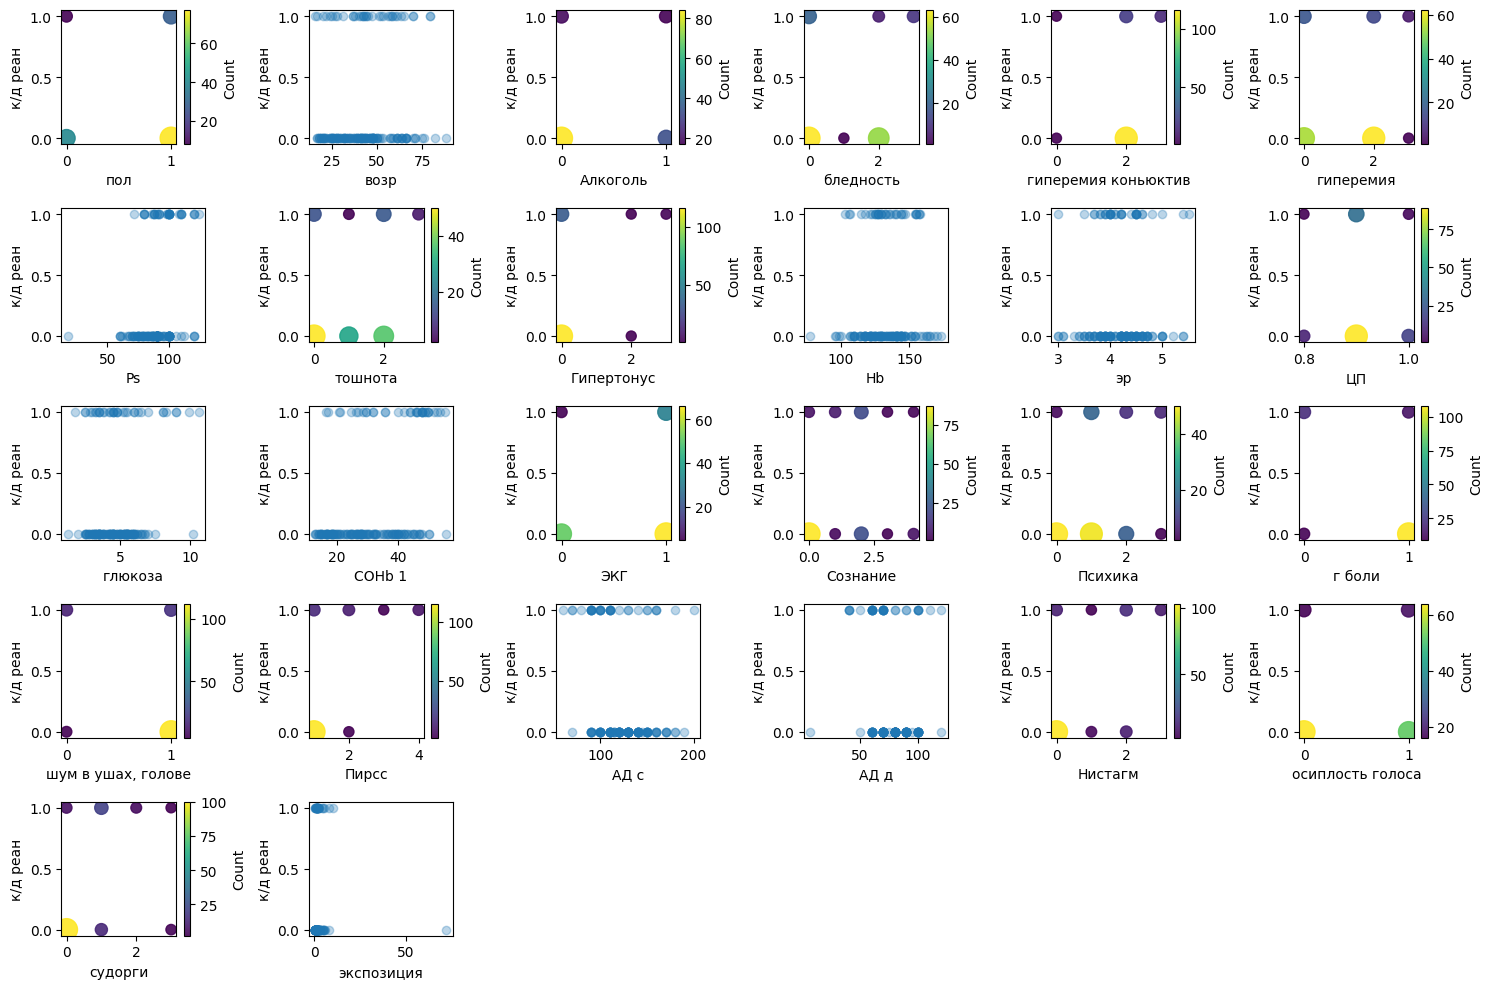

In [106]:
features = X_eposion.columns

plt.figure(figsize=(15, 10))

for i, feature in enumerate(features, 1):
    plt.subplot(5, 6, i)

    x = X_eposion[feature]
    y = y_exp

    # число уникальных значений без NaN
    n_unique = x.nunique(dropna=True)

    if n_unique <= 5:
        # группируем одинаковые пары (x, y)
        df = pd.DataFrame({'x': x, 'y': y})
        counts = df.groupby(['x', 'y']).size().reset_index(name='count')

        sc = plt.scatter(
            counts['x'],
            counts['y'],
            c=counts['count'],
            s=50 + 200 * counts['count'] / counts['count'].max(),
            cmap='viridis',
            alpha=0.9
        )

        plt.colorbar(sc, label='Count')
    else:
        # обычный scatter для вещественных признаков
        plt.scatter(x, y, alpha=0.3)

    plt.xlabel(feature)
    plt.ylabel(y_exp.name)

plt.tight_layout()
plt.show()

In [53]:
def plot_corr(X, y, title=None, nums=False):
  X_num = X.select_dtypes(include="number")
  X_num['target'] = y
  corr = X_num.corr(method="pearson")

  plt.figure(figsize=(20, 12))
  sns.heatmap(corr, cmap="coolwarm",  vmin=-1, vmax=1, annot=nums, center=0, fmt=".2f", square=True)

  plt.title(title)
  plt.tight_layout()
  plt.show()

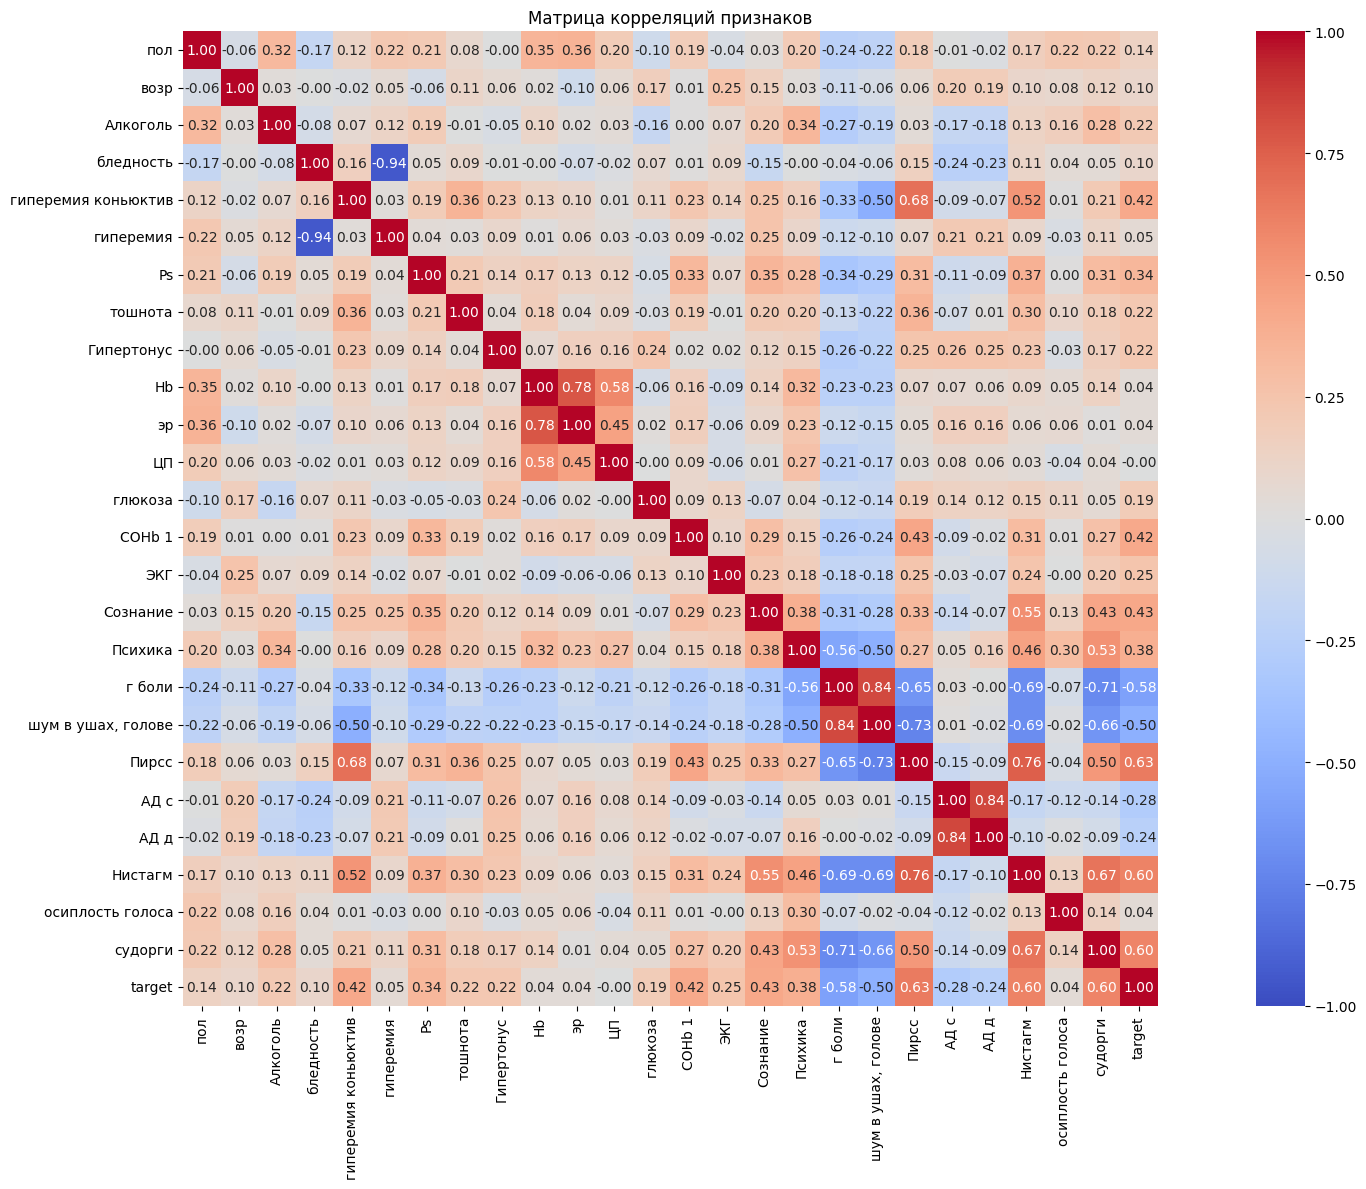

In [54]:
plot_corr(X, y, "Матрица корреляций признаков", True)

##Отбор признаков

Осуществляется L1-регрессией по стандартизированным вещественным + сырым бинарным признакам


In [96]:
# standartization_need
scale_cols = ['возр',
              #'экспозиция',
              'бледность', 'гиперемия коньюктив', 'гиперемия', 'тошнота', 'Ps', 'Гипертонус', 'Hb','эр','ЦП','глюкоза','COHb 1', 'Сознание',
          'Психика','Пирсс', 'АД с', 'АД д', 'судорги',  'Нистагм']

def bootstrap_feature_selection(X, y, n_iter=10000, eps=1e-5):
    coefs = np.zeros((n_iter, X.shape[1]))
    for i in range(n_iter):
        X_boot, y_boot = resample(X, y, replace=True, n_samples=len(X), stratify=y, random_state=int(rng.integers(0, 2**31 - 1)))
        X_boot = X_boot.copy()
        scaler = StandardScaler()
        X_boot[scale_cols] = scaler.fit_transform(X_boot[scale_cols])
        model = LogisticRegression(penalty='l1', solver='liblinear', C=1.0, max_iter=2000)
        model.fit(X_boot, y_boot)
        coefs[i] = model.coef_[0]

    result = pd.DataFrame({
        'feature': X.columns,
        'selection_freq': np.round((np.abs(coefs) > eps).mean(axis=0), 6),
        'mean_coef': coefs.mean(axis=0),
        'std_coef': coefs.std(axis=0),
        'positive_freq': (coefs > eps).mean(axis=0),
        'negative_freq': (coefs < -eps).mean(axis=0)
    })

    result = result.sort_values('selection_freq', ascending=False).reset_index(drop=True)

    return result

In [123]:
result = bootstrap_feature_selection(X_l1_reg, y_l1_reg)
result

,feature,selection_freq,mean_coef,std_coef,positive_freq,negative_freq
0,Пирсс,0.9459,1.329057,0.831392,0.9459,0.0000
1,COHb 1,0.9187,0.542229,0.365724,0.9157,0.0030
2,судорги,0.9179,0.863694,0.654080,0.9031,0.0148
3,АД с,0.8685,-0.829232,0.564737,0.0000,0.8685
4,АД д,0.8497,-0.631224,0.514527,0.0000,0.8497
5,ЦП,0.8318,-0.433361,0.358041,0.0012,0.8306
6,Сознание,0.8225,0.392707,0.333432,0.8087,0.0138
7,Гипертонус,0.8022,0.379030,0.313381,0.7922,0.0100
8,Ps,0.7969,0.403199,0.387473,0.7665,0.0304
9,глюкоза,0.7786,0.280433,0.289834,0.7371,0.0415


In [129]:
best_features = result[:10]['feature']
print(best_features)

0         Пирсс
1        COHb 1
2       судорги
3          АД с
4          АД д
5            ЦП
6      Сознание
7    Гипертонус
8            Ps
9       глюкоза
Name: feature, dtype: object


In [120]:
result_exposion = bootstrap_feature_selection(X_eposion_no_nan, y_exp_no_nan)
result_exposion

,feature,selection_freq,mean_coef,std_coef,positive_freq,negative_freq
0,судорги,0.9959,1.639076,0.513842,0.9959,0.0000
1,гиперемия коньюктив,0.9138,0.605961,0.488565,0.9138,0.0000
2,АД с,0.8987,-1.090599,0.631227,0.0000,0.8987
3,АД д,0.8271,-0.609004,0.561961,0.0000,0.8271
4,COHb 1,0.7994,0.426719,0.386192,0.7957,0.0037
5,Ps,0.7822,0.388122,0.332419,0.7792,0.0030
6,Сознание,0.7767,0.296459,0.270223,0.7752,0.0015
7,Пирсс,0.7734,0.713289,0.631269,0.7734,0.0000
8,глюкоза,0.7356,0.352681,0.337383,0.7288,0.0068
9,возр,0.7130,0.296338,0.322819,0.6901,0.0229


## Сэмплинги


In [142]:
X, y = prepare_to_num(best_features.to_list('судорги', ''))
print(X.shape)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y)
X_train, X_test = impute_nan_train_test(X_train, X_test)



(153, 10)


In [150]:
samplers = {
    "ROS": RandomOverSampler(),
    "SMOTE": SMOTE(k_neighbors=5),
    "ADASYN": ADASYN(n_neighbors=5)}

sample_train_data = {'NO_SAMPLING': {'X_train': X_train, 'y_train': y_train} }

for name, sampler in samplers.items():
    X_res, y_res = sampler.fit_resample(X_train, y_train)
    print(name, X_res.shape, y_res.sum())
    sample_train_data[name] = {'X_train': X_res, 'y_train': y_res}

ROS (186, 10) 93
SMOTE (186, 10) 93
ADASYN (188, 10) 95


##

## Бустинги

Подготовка и определение кроссвалидации

#### Фукнции

In [153]:
dict_k_fold_split = {"NO_SAMPLING": 5,
                    "ROS": 8,
                    "SMOTE": 8,
                    "ADASYN": 8}
threshold = 0.5
y = np.asarray(y)

def run_experiment(X, y, model_type, sample_type, params, print_folds_score=False, print_all=False):
  skf = StratifiedKFold(n_splits=dict_k_fold_split[sample_type], shuffle=True)
  oof_probs = np.zeros(len(y))
  fold_scores = []
  best_iter = []
  model_name = model_type.__module__.split('.')[0]

  for fold, (train_idx, val_idx) in enumerate(skf.split(X, y), start=1):
      X_train = X.iloc[train_idx]
      X_val = X.iloc[val_idx]
      y_train = y[train_idx]
      y_val = y[val_idx]
      X_train, y_train = samplers[sample_type].fit_resample(X_train, y_train)
      model = model_type(**params)

      # CatBoost
      if model_name == "catboost":
        model.fit(X_train, y_train, eval_set=(X_val, y_val), early_stopping_rounds=100, verbose=False)
        best_iter = model.tree_count_

      # LightGBM
      elif model_name == "lightgbm":
        model.fit(X_train, y_train, eval_set=[(X_val, y_val)],
                callbacks=[lgb.early_stopping(100, verbose=False), lgb.log_evaluation(0)])
        best_iter = model.best_iteration_

      # XGBoost
      elif model_name == "xgboost":
        model.set_params(early_stopping_rounds=100)
        model.fit(X_train, y_train, eval_set=[(X_val, y_val)],verbose=False)
        best_iter = model.best_iteration

      probs = model.predict_proba(X_val)[:, 1]
      oof_probs[val_idx] = probs

      ap = average_precision_score(y_val, probs)
      fold_scores.append(ap)

      if print_folds_score:
        print(f"Fold {fold}: AP = {ap:.4f}")

  # Итоговые метрики
  preds = (oof_probs >= threshold).astype(int)

  tn, fp, fn, tp = confusion_matrix(y, preds, labels=[0, 1]).ravel()
  ap = average_precision_score(y, oof_probs)
  roc_auc = roc_auc_score(y, oof_probs)
  recall = recall_score(y, preds)
  precision = precision_score(y, preds, zero_division=0)
  f2 = fbeta_score(y, preds, beta=2)
  specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
  bs = brier_score_loss(y, oof_probs)

  if print_all:
      print(f"AP: {ap:.4f}")
      print(f"ROC-AUC: {roc_auc:.4f}")
      print(f"Recall: {recall:.4f}")
      print(f"Specificity: {specificity:.4f}")
      print(f"Precision: {precision:.4f}")
      print(f"F2: {f2:.4f}")
      print(f"Brier Score: {bs:.4f}")
      print("\nConfusion matrix:")
      print(confusion_matrix(y, preds))
      print(f"\nMean fold AP: {np.mean(fold_scores):.4f}")
      print(f"Std fold AP: {np.std(fold_scores):.4f}")


  return {
        "AP": ap,
        "ROC_AUC": roc_auc,
        "Recall": recall,
        "F2": f2,
        "Specificity": specificity,
        "Precision": precision,
        "Brier_Score": bs,
        "Mean_fold_AP": np.mean(fold_scores),
        "Std_fold_AP": np.std(fold_scores),
    }


experiments = []

def run_and_record(X, y, model_type, sample_type, params, print_folds_score=False, print_all=False):
    metrics = run_experiment(X,y, model_type, params, print_folds_score, print_all)
    experiment = {
        "Model": model_type.__name__,
        "Sampling": sample_type,
        "Params": str(params),
        **{k: v for k, v in metrics.items()}}

    experiments.append(experiment)
    return metrics

In [154]:
def show_experiments():
    if not experiments:
        print("Нет сохранённых экспериментов.")
        return
    df = pd.DataFrame(experiments)
    higher_is_better = ["AP","ROC_AUC","Recall","F2", "Specificity","Precision", "Mean_fold_AP"]

    lower_is_better = [ "Brier_Score","Std_fold_AP"]

    def highlight_best(s):
        if s.name in higher_is_better:
            best = s.max()
        elif s.name in lower_is_better:
            best = s.min()
        else:
            return [""] * len(s)
        return [("background-color: #b7e4c7; "
                  "color: #1b4332; font-weight: bold") if pd.notna(v) and v == best else "" for v in s]
    metric_columns = higher_is_better + lower_is_better
    return (df.style.apply(highlight_best, subset=metric_columns).format({col: "{:.4f}" for col in metric_columns}))


def export_experiments(filename="experiments.csv"):
    if not experiments:
        print("Нет экспериментов для экспорта.")
        return
    df = pd.DataFrame(experiments)
    df.to_csv(filename, index=False, encoding="utf-8-sig")
    print(f"Таблица сохранена: {filename}")
    display(FileLink(filename))



## Catboost

In [156]:
cat_params = {
    "iterations": 1000,
    "depth": 4,
    "learning_rate": 0.03,
    "l2_leaf_reg": 5,
    "loss_function": "Logloss",
    "eval_metric": "PRAUC",
    "auto_class_weights": "SqrtBalanced",
    "random_seed": 42
}

cat_results = run_and_record(CatBoostClassifier,  "NO_SAMPLING",  cat_params, "defolt", print_all=True)



TypeError: run_and_record() missing 1 required positional argument: 'params'

In [ ]:
cat_params = {
    "iterations": 1000,
    "depth": 5,
    "learning_rate": 0.03,
    "l2_leaf_reg": 5,
    "loss_function": "Logloss",
    "eval_metric": "PRAUC",
    "auto_class_weights": "SqrtBalanced",
    "random_seed": 42
}

cat_results = run_and_record(X_2, y,CatBoostClassifier,cat_params, print_all=True)

AP: 0.7834
ROC-AUC: 0.8910
Recall: 0.6111
Specificity: 0.9583
Precision: 0.8148
F2: 0.6433
Brier Score: 0.1488

Confusion matrix:
[[115   5]
 [ 14  22]]

Mean fold AP: 0.8556
Std fold AP: 0.1340


In [ ]:
cat_params = {
    "iterations": 1000,
    "depth": 3,
    "learning_rate": 0.1,
    "l2_leaf_reg": 5,
    "loss_function": "Logloss",
    "eval_metric": "PRAUC",
    "auto_class_weights": "SqrtBalanced",
    "random_seed": 42
}

cat_results = run_and_record(X_2, y,CatBoostClassifier,cat_params, print_all=True)

AP: 0.7837
ROC-AUC: 0.9060
Recall: 0.6667
Specificity: 0.9500
Precision: 0.8000
F2: 0.6897
Brier Score: 0.1122

Confusion matrix:
[[114   6]
 [ 12  24]]

Mean fold AP: 0.8483
Std fold AP: 0.1532


In [ ]:
cat_params = {
    "iterations": 1000,
    "depth": 3,
    "learning_rate": 0.1,
    "l2_leaf_reg": 10,
    "loss_function": "Logloss",
    "eval_metric": "PRAUC",
    "auto_class_weights": "SqrtBalanced",
    "random_seed": 42
}

cat_results = run_and_record(X_2, y,CatBoostClassifier,cat_params, print_all=True)

AP: 0.7675
ROC-AUC: 0.8938
Recall: 0.6944
Specificity: 0.9417
Precision: 0.7812
F2: 0.7102
Brier Score: 0.1283

Confusion matrix:
[[113   7]
 [ 11  25]]

Mean fold AP: 0.8488
Std fold AP: 0.1521


In [ ]:
cat_params = {
    "iterations": 1000,
    "depth": 5,
    "learning_rate": 0.1,
    "l2_leaf_reg": 10,
    "loss_function": "Logloss",
    "eval_metric": "PRAUC",
    "auto_class_weights": "SqrtBalanced",
    "random_seed": 42
}

cat_results = run_and_record(X_2, y,CatBoostClassifier,cat_params, print_all=True)

AP: 0.8159
ROC-AUC: 0.9139
Recall: 0.6667
Specificity: 0.9333
Precision: 0.7500
F2: 0.6818
Brier Score: 0.1030

Confusion matrix:
[[112   8]
 [ 12  24]]

Mean fold AP: 0.8597
Std fold AP: 0.1333


In [ ]:
cat_params = {
    "iterations": 100,
    "depth": 4,
    "learning_rate": 0.9,
    "l2_leaf_reg": 10,
    "loss_function": "Logloss",
    "eval_metric": "PRAUC",
    "auto_class_weights": "SqrtBalanced",
    "random_seed": 42
}

cat_results = run_and_record(X_2, y,CatBoostClassifier,cat_params, print_all=True)

AP: 0.8090
ROC-AUC: 0.9177
Recall: 0.6667
Specificity: 0.9250
Precision: 0.7273
F2: 0.6780
Brier Score: 0.0916

Confusion matrix:
[[111   9]
 [ 12  24]]

Mean fold AP: 0.8520
Std fold AP: 0.1496


## LightGBM

In [ ]:
X_2_lgb = X_2.copy()

X_2_lgb.columns = [
    f"feature_{i}" for i in range(X_2_lgb.shape[1])
]

lgb_params = {
    "n_estimators": 1000,
    "max_depth": 4,
    "learning_rate": 0.03,
    "class_weight": "balanced",
    "verbosity": -1
}

lgb_results = run_and_record(X_2_lgb, y, LGBMClassifier, lgb_params, print_all=True)

AP: 0.8251
ROC-AUC: 0.9178
Recall: 0.7222
Specificity: 0.9083
Precision: 0.7027
F2: 0.7182
Brier Score: 0.0942

Confusion matrix:
[[109  11]
 [ 10  26]]

Mean fold AP: 0.8390
Std fold AP: 0.0821


In [ ]:
lgb_params = {
    "n_estimators": 1000,
    "max_depth": 5,
    "learning_rate": 0.03,
    "class_weight": "balanced",
    "verbosity": -1
}

lgb_results = run_and_record(X_2_lgb, y, LGBMClassifier, lgb_params, print_all=True)

AP: 0.8184
ROC-AUC: 0.9160
Recall: 0.7222
Specificity: 0.9083
Precision: 0.7027
F2: 0.7182
Brier Score: 0.0969

Confusion matrix:
[[109  11]
 [ 10  26]]

Mean fold AP: 0.8363
Std fold AP: 0.0841


In [ ]:
lgb_params = {
    "n_estimators": 100,
    "max_depth": 4,
    "learning_rate": 0.2,
    "class_weight": "balanced",
    "verbosity": -1
}

lgb_results = run_and_record(X_2_lgb, y, LGBMClassifier, lgb_params, print_all=True)

AP: 0.8202
ROC-AUC: 0.9118
Recall: 0.7222
Specificity: 0.9167
Precision: 0.7222
F2: 0.7222
Brier Score: 0.0950

Confusion matrix:
[[110  10]
 [ 10  26]]

Mean fold AP: 0.8382
Std fold AP: 0.0777


## XGBOOST

In [ ]:
xgb_params = {
    "n_estimators": 1000,
    "max_depth": 4,
    "learning_rate": 0.03,
    "eval_metric": "aucpr",
    "scale_pos_weight": (y == 0).sum() / (y == 1).sum()
}

xgb_results = run_and_record(
    X_2, y,
    XGBClassifier,
    xgb_params,
    print_all=True
)

AP: 0.6134
ROC-AUC: 0.8010
Recall: 0.6944
Specificity: 0.8833
Precision: 0.6410
F2: 0.6831
Brier Score: 0.1751

Confusion matrix:
[[106  14]
 [ 11  25]]

Mean fold AP: 0.7872
Std fold AP: 0.1630


In [ ]:
xgb_params = {
    "n_estimators": 1000,
    "max_depth": 4,
    "learning_rate": 0.1,
    "eval_metric": "aucpr",
    "scale_pos_weight": (y == 0).sum() / (y == 1).sum()
}

xgb_results = run_and_record(
    X_2, y,
    XGBClassifier,
    xgb_params,
    print_all=True
)

AP: 0.6327
ROC-AUC: 0.8071
Recall: 0.6944
Specificity: 0.8833
Precision: 0.6410
F2: 0.6831
Brier Score: 0.1619

Confusion matrix:
[[106  14]
 [ 11  25]]

Mean fold AP: 0.8053
Std fold AP: 0.1405


In [ ]:
xgb_params = {
    "n_estimators": 90,
    "max_depth": 4,
    "learning_rate": 0.1,
    "eval_metric": "aucpr",
    "scale_pos_weight": (y == 0).sum() / (y == 1).sum()
}

xgb_results = run_and_record(
    X_2, y,
    XGBClassifier,
    xgb_params,
    print_all=True
)

AP: 0.6050
ROC-AUC: 0.7943
Recall: 0.6944
Specificity: 0.8750
Precision: 0.6250
F2: 0.6793
Brier Score: 0.1637

Confusion matrix:
[[105  15]
 [ 11  25]]

Mean fold AP: 0.8023
Std fold AP: 0.1375


In [ ]:
xgb_params = {
    "n_estimators": 90,
    "max_depth": 4,
    "learning_rate": 0.5,
    "eval_metric": "aucpr",
    "scale_pos_weight": (y == 0).sum() / (y == 1).sum()
}

xgb_results = run_and_record(
    X_2, y,
    XGBClassifier,
    xgb_params,
    print_all=True
)

AP: 0.6455
ROC-AUC: 0.8282
Recall: 0.6944
Specificity: 0.9000
Precision: 0.6757
F2: 0.6906
Brier Score: 0.1323

Confusion matrix:
[[108  12]
 [ 11  25]]

Mean fold AP: 0.8070
Std fold AP: 0.1480


In [ ]:
xgb_params = {
    "n_estimators": 90,
    "max_depth": 4,
    "learning_rate": 0.01,
    "eval_metric": "aucpr",
    "scale_pos_weight": (y == 0).sum() / (y == 1).sum()
}

xgb_results = run_and_record(
    X_2, y,
    XGBClassifier,
    xgb_params,
    print_all=True
)

AP: 0.5136
ROC-AUC: 0.7701
Recall: 0.5833
Specificity: 0.8417
Precision: 0.5250
F2: 0.5707
Brier Score: 0.2327

Confusion matrix:
[[101  19]
 [ 15  21]]

Mean fold AP: 0.6899
Std fold AP: 0.1954


In [ ]:
show_experiments()

,Model,Params,AP,ROC_AUC,Recall,F2,Specificity,Precision,Brier_Score,Mean_fold_AP,Std_fold_AP
0,CatBoostClassifier,"{'iterations': 1000, 'depth': 4, 'learning_rate': 0.03, 'l2_leaf_reg': 5, 'loss_function': 'Logloss', 'eval_metric': 'PRAUC', 'auto_class_weights': 'SqrtBalanced', 'random_seed': 42}",0.7631,0.8811,0.6111,0.6358,0.9417,0.7586,0.1471,0.8617,0.1500
1,CatBoostClassifier,"{'iterations': 1000, 'depth': 5, 'learning_rate': 0.03, 'l2_leaf_reg': 5, 'loss_function': 'Logloss', 'eval_metric': 'PRAUC', 'auto_class_weights': 'SqrtBalanced', 'random_seed': 42}",0.7834,0.8910,0.6111,0.6433,0.9583,0.8148,0.1488,0.8556,0.1340
2,CatBoostClassifier,"{'iterations': 1000, 'depth': 3, 'learning_rate': 0.1, 'l2_leaf_reg': 5, 'loss_function': 'Logloss', 'eval_metric': 'PRAUC', 'auto_class_weights': 'SqrtBalanced', 'random_seed': 42}",0.7837,0.9060,0.6667,0.6897,0.9500,0.8000,0.1122,0.8483,0.1532
3,CatBoostClassifier,"{'iterations': 1000, 'depth': 3, 'learning_rate': 0.1, 'l2_leaf_reg': 10, 'loss_function': 'Logloss', 'eval_metric': 'PRAUC', 'auto_class_weights': 'SqrtBalanced', 'random_seed': 42}",0.7675,0.8938,0.6944,0.7102,0.9417,0.7812,0.1283,0.8488,0.1521
4,CatBoostClassifier,"{'iterations': 1000, 'depth': 5, 'learning_rate': 0.1, 'l2_leaf_reg': 10, 'loss_function': 'Logloss', 'eval_metric': 'PRAUC', 'auto_class_weights': 'SqrtBalanced', 'random_seed': 42}",0.8159,0.9139,0.6667,0.6818,0.9333,0.7500,0.1030,0.8597,0.1333
5,CatBoostClassifier,"{'iterations': 100, 'depth': 4, 'learning_rate': 0.9, 'l2_leaf_reg': 10, 'loss_function': 'Logloss', 'eval_metric': 'PRAUC', 'auto_class_weights': 'SqrtBalanced', 'random_seed': 42}",0.8090,0.9177,0.6667,0.6780,0.9250,0.7273,0.0916,0.8520,0.1496
6,LGBMClassifier,"{'n_estimators': 1000, 'max_depth': 4, 'learning_rate': 0.03, 'class_weight': 'balanced', 'verbosity': -1}",0.8251,0.9178,0.7222,0.7182,0.9083,0.7027,0.0942,0.8390,0.0821
7,LGBMClassifier,"{'n_estimators': 1000, 'max_depth': 5, 'learning_rate': 0.03, 'class_weight': 'balanced', 'verbosity': -1}",0.8184,0.9160,0.7222,0.7182,0.9083,0.7027,0.0969,0.8363,0.0841
8,LGBMClassifier,"{'n_estimators': 1000, 'max_depth': 4, 'learning_rate': 0.1, 'class_weight': 'balanced', 'verbosity': -1}",0.8278,0.9204,0.7222,0.7182,0.9083,0.7027,0.0933,0.8408,0.0828
9,LGBMClassifier,"{'n_estimators': 1000, 'max_depth': 4, 'learning_rate': 0.5, 'class_weight': 'balanced', 'verbosity': -1}",0.8237,0.9225,0.7500,0.7377,0.9000,0.6923,0.0945,0.8255,0.0951


In [ ]:
export_experiments()

Таблица сохранена: experiments.csv


/content/experiments.csv